# Day 60 — CNN Architectures & ResNet-34
- Recognize the design ideas behind LeNet-5, AlexNet, VGGNet, GoogLeNet, ResNet, Xception, and SENet.
- Explain why deep plain CNNs can become difficult to optimize and how residual/skip connections help.
- Implement a ResNet-34-style model with Keras functional API.
- Train and evaluate a practical CIFAR-10 version, while understanding how it differs from the original ImageNet ResNet-34.

## 1. Classic CNN architectures — the big picture

| Architecture | Main idea | Why it mattered |
|---|---|---|
| **LeNet-5** | Early convolution + pooling stack | Established a practical pattern for digit recognition |
| **AlexNet** | Deeper/wider CNN, ReLU, dropout, GPU training, data augmentation | Helped trigger the modern deep-learning boom after ImageNet 2012 |
| **VGGNet** | Repeated small 3×3 convolutions in simple blocks | Demonstrated that depth and a consistent design can be powerful; parameter-heavy |
| **GoogLeNet / Inception** | Parallel filters and pooling inside Inception modules; 1×1 convolutions reduce channel count | Increased representational variety with better compute efficiency |
| **ResNet** | Identity shortcut adds a block's input to its transformed output | Makes very deep networks easier to optimize |
| **Xception** | Depthwise-separable convolutions, inspired by an “extreme” Inception design | Separates spatial filtering from channel mixing |
| **SENet** | Squeeze-and-Excitation recalibrates channels using global context | Lets a network emphasize informative feature channels |

### A useful timeline
- **LeNet-5 (1990s):** foundational CNN design.
- **AlexNet (2012):** large-scale ImageNet success.
- **VGGNet and GoogLeNet (2014):** depth and multi-branch efficiency.
- **ResNet (2015):** residual learning enables much deeper models.
- **Xception (2016) and SENet (2017):** refine how spatial and channel information are processed.

**Study prompt:** For each architecture, be able to explain the *problem it was trying to solve*, not just its name.

## 2. Residual block intuition

A plain block learns a transformation \(H(x)\). A residual block instead learns a change to the input:

\[
y = F(x) + x
\]

where \(F(x)\) is the residual branch (for example, two convolution layers). The shortcut carries \(x\) around the convolutions, then the two paths are added.

**Why this helps**
1. If the identity mapping is already useful, the residual branch can learn a small correction instead of reconstructing the entire mapping.
2. The shortcut creates a direct path for information and gradients.
3. When feature-map dimensions change, a projection shortcut (usually a 1×1 convolution with the appropriate stride) matches the shortcut's shape to the residual branch.

**Shape rule:** element-wise addition requires identical tensor shapes. For example, a transition from `(32, 32, 32)` to `(16, 16, 64)` needs a stride-2 convolution in the main path and a stride-2 1×1 projection in the shortcut.

A residual block is not simply concatenation: it **adds** corresponding values.

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__ if hasattr(keras, "__version__") else "version bundled with TensorFlow")

TensorFlow: 2.21.0
Keras: 3.15.1


## 3. Load data — quick local mode by default

**This notebook is configured to run locally without waiting for a CIFAR-10 download.**

- `QUICK_MODE = True` and `USE_REAL_CIFAR10 = False` use a tiny, generated dataset. This is only for checking that the ResNet-34 architecture and training pipeline run; the accuracy is **not meaningful**.
- To train on real images, set `USE_REAL_CIFAR10 = True`. The first download can take time; later runs should use Keras' local cache.
- With real CIFAR-10, `QUICK_MODE = True` uses a subset to reduce CPU training time. Set `QUICK_MODE = False` to use the full dataset and a longer training run.

The image tensors are normalized to `[0, 1]`. The official CIFAR-10 test set is kept separate from training.

In [12]:
from pathlib import Path
import numpy as np
import time

# ---- Choose your run mode ----
QUICK_MODE = True
USE_REAL_CIFAR10 = False  # Change to True when you want real CIFAR-10 images

SEED = 42
rng = np.random.default_rng(SEED)
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

start_time = time.perf_counter()

if USE_REAL_CIFAR10:
    print("Loading CIFAR-10. First-time download may take a while...")
    (x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

    y_train = y_train.squeeze().astype("int32")
    y_test = y_test.squeeze().astype("int32")

    if QUICK_MODE:
        # Small subset for faster local experiments
        x_train, y_train = x_train[:2000], y_train[:2000]
        x_test, y_test = x_test[:500], y_test[:500]

    # Convert and normalize without creating an extra division array
    x_train = x_train.astype(np.float32)
    x_train *= (1.0 / 255.0)
    x_test = x_test.astype(np.float32)
    x_test *= (1.0 / 255.0)

    print("Dataset mode: REAL CIFAR-10")
else:
    # No download or network access required. Random data tests the code path only.
    # The resulting model accuracy does not measure real image classification.
    n_train = 256 if QUICK_MODE else 1000
    n_test = 64 if QUICK_MODE else 200
    x_train = rng.integers(0, 256, size=(n_train, 32, 32, 3), dtype=np.uint8).astype(np.float32)
    x_test = rng.integers(0, 256, size=(n_test, 32, 32, 3), dtype=np.uint8).astype(np.float32)
    x_train *= (1.0 / 255.0)
    x_test *= (1.0 / 255.0)
    y_train = rng.integers(0, 10, size=n_train, dtype=np.int32)
    y_test = rng.integers(0, 10, size=n_test, dtype=np.int32)
    print("Dataset mode: SYNTHETIC QUICK DEMO (no CIFAR-10 download)")
    print("Note: accuracy on generated random images is not meaningful.")

print(f"Data setup time: {time.perf_counter() - start_time:.2f} seconds")
print("Train:", x_train.shape, y_train.shape)
print("Test: ", x_test.shape, y_test.shape)
print("Pixel range:", float(x_train.min()), "to", float(x_train.max()))


Dataset mode: SYNTHETIC QUICK DEMO (no CIFAR-10 download)
Note: accuracy on generated random images is not meaningful.
Data setup time: 0.00 seconds
Train: (256, 32, 32, 3) (256,)
Test:  (64, 32, 32, 3) (64,)
Pixel range: 0.0 to 1.0


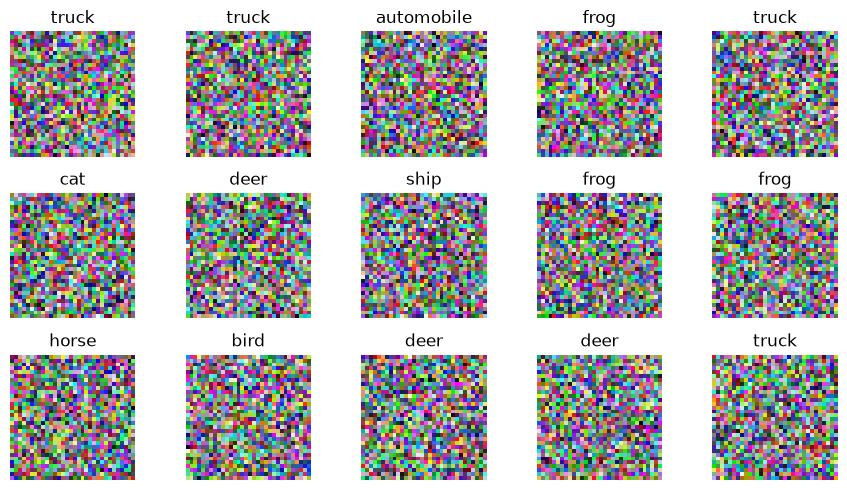

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Build a basic residual block

This is a **basic block** with two 3×3 convolutions, as used in ResNet-34. Batch normalization stabilizes training; ReLU supplies non-linearity. The shortcut uses identity when dimensions match and a learned 1×1 projection when they do not.

In [4]:
def residual_block(x, filters, stride=1, name=None):
    """Two-convolution ResNet basic block.

    Args:
        x: input tensor.
        filters: number of output channels.
        stride: 1 for same spatial size; 2 for downsampling.
        name: optional name prefix.
    """
    shortcut = x
    prefix = name or "res"

    # Residual branch: 3x3 convolution -> BN -> ReLU -> 3x3 convolution -> BN
    y = layers.Conv2D(
        filters, kernel_size=3, strides=stride, padding="same",
        use_bias=False, kernel_initializer="he_normal",
        name=f"{prefix}_conv1"
    )(x)
    y = layers.BatchNormalization(name=f"{prefix}_bn1")(y)
    y = layers.Activation("relu", name=f"{prefix}_relu1")(y)

    y = layers.Conv2D(
        filters, kernel_size=3, strides=1, padding="same",
        use_bias=False, kernel_initializer="he_normal",
        name=f"{prefix}_conv2"
    )(y)
    y = layers.BatchNormalization(name=f"{prefix}_bn2")(y)

    # Projection shortcut when spatial size or channel count changes
    if stride != 1 or x.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters, kernel_size=1, strides=stride, padding="same",
            use_bias=False, kernel_initializer="he_normal",
            name=f"{prefix}_proj_conv"
        )(shortcut)
        shortcut = layers.BatchNormalization(name=f"{prefix}_proj_bn")(shortcut)

    y = layers.Add(name=f"{prefix}_add")([y, shortcut])
    return layers.Activation("relu", name=f"{prefix}_out")(y)

In [5]:
# Shape experiment: a same-shape block and a downsampling/projection block
input_same = keras.Input(shape=(32, 32, 32))
output_same = residual_block(input_same, filters=32, stride=1, name="demo_same")
demo_same = keras.Model(input_same, output_same)
print("Same-shape block:", demo_same.output_shape)

input_down = keras.Input(shape=(32, 32, 32))
output_down = residual_block(input_down, filters=64, stride=2, name="demo_down")
demo_down = keras.Model(input_down, output_down)
print("Downsampling block:", demo_down.output_shape)

Same-shape block: (None, 32, 32, 32)
Downsampling block: (None, 16, 16, 64)


## 5. Assemble ResNet-34

The canonical ResNet-34 uses basic-block counts **[3, 4, 6, 3]** across four stages. The first block in stages 2–4 downsamples with stride 2 and increases the channel count. A global average pool and dense classifier follow the residual stages.

For CIFAR-10, we use a small 3×3 stem with stride 1 and omit the original ImageNet stem's 7×7 stride-2 convolution and max-pooling; these would shrink 32×32 images too aggressively. This is a CIFAR-adapted ResNet-34, not a byte-for-byte reproduction of the original ImageNet model.

In [6]:
# Keep the ResNet-34 block pattern, but use fewer channels in quick mode.
# Increase BASE_FILTERS for a larger model if your computer has enough resources.
BASE_FILTERS = 8 if QUICK_MODE else 32
BLOCKS_PER_STAGE = (3, 4, 6, 3)

def build_resnet34(input_shape=(32, 32, 3), num_classes=10, base_filters=32):
    inputs = keras.Input(shape=input_shape, name="image")

    # CIFAR-friendly stem: 3x3 convolution, stride 1 (preserves 32x32 resolution)
    x = layers.Conv2D(
        base_filters, 3, strides=1, padding="same", use_bias=False,
        kernel_initializer="he_normal", name="stem_conv"
    )(inputs)
    x = layers.BatchNormalization(name="stem_bn")(x)
    x = layers.Activation("relu", name="stem_relu")(x)

    # Four stages; first block of stages 2-4 downsamples
    for stage_index, num_blocks in enumerate(BLOCKS_PER_STAGE):
        filters = base_filters * (2 ** stage_index)
        for block_index in range(num_blocks):
            stride = 2 if stage_index > 0 and block_index == 0 else 1
            x = residual_block(
                x, filters=filters, stride=stride,
                name=f"stage{stage_index + 1}_block{block_index + 1}"
            )

    x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name="ResNet34_CIFAR10")

model = build_resnet34(base_filters=BASE_FILTERS)
print(f"Quick mode: {QUICK_MODE} | Base filters: {BASE_FILTERS}")
model.summary()


Quick mode: True | Base filters: 8


Model: "ResNet34_CIFAR10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 32, 32, 3) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 32, 32, 8) │        216 │ image[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 32, 32, 8) │         32 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_relu           │ (None, 32, 32, 8) │          0 │ stem_bn[0][0]     │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block1_conv1 │ (None, 32, 32, 8) │        576 │ stem_relu[0][0]   │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block1_bn1   │ (None, 32, 32, 8) │         32 │ stage1_block1_co… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block1_relu1 │ (None, 32, 32, 8) │          0 │ stage1_block1_bn… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block1_conv2 │ (None, 32, 32, 8) │        576 │ stage1_block1_re… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block1_bn2   │ (None, 32, 32, 8) │         32 │ stage1_block1_co… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block1_add   │ (None, 32, 32, 8) │          0 │ stage1_block1_bn… │
│ (Add)               │                   │            │ stem_relu[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block1_out   │ (None, 32, 32, 8) │          0 │ stage1_block1_ad… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block2_conv1 │ (None, 32, 32, 8) │        576 │ stage1_block1_ou… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block2_bn1   │ (None, 32, 32, 8) │         32 │ stage1_block2_co… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block2_relu1 │ (None, 32, 32, 8) │          0 │ stage1_block2_bn… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block2_conv2 │ (None, 32, 32, 8) │        576 │ stage1_block2_re… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block2_bn2   │ (None, 32, 32, 8) │         32 │ stage1_block2_co… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_block2_add   │ (None, 32, 32, 8) │          0 │ stage1_block2_bn… │
│ (Add)               │                   │            │ stage1_block1_ou… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 337,282 (1.29 MB)

 Trainable params: 335,154 (1.28 MB)

 Non-trainable params: 2,128 (8.31 KB)

### Architecture checks
- Stage block counts: `3 + 4 + 6 + 3 = 16` residual blocks.
- Each basic block contains two 3×3 convolutions: `16 × 2 = 32` convolutions.
- Add the stem convolution and final dense layer: the conventional naming **ResNet-34** counts 34 weighted layers (32 block convolutions + stem convolution + dense classifier).
- Projection shortcuts add extra convolution layers at stage transitions, but are not included in that common 34-layer count.

Try changing `BASE_FILTERS` to `64` only if memory and training time permit.

## 6. Compile and train

This baseline uses Adam for convenience. The original ResNet paper used SGD with momentum and a carefully scheduled learning rate; later, compare optimizers and schedules as an experiment. Training a deep model from scratch may take a while, so start with a small epoch count and use callbacks.

In [7]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=2, restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5
    )
]

# Quick mode is for testing the pipeline, not benchmarking accuracy.
EPOCHS = 1 if QUICK_MODE else 10
BATCH_SIZE = 32 if QUICK_MODE else 64

history = model.fit(
    x_train, y_train,
    validation_split=0.1,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)


8/8 ━━━━━━━━━━━━━━━━━━━━ 11s 132ms/step - accuracy: 0.0913 - loss: 2.7234 - val_accuracy: 0.1538 - val_loss: 40.6835 - learning_rate: 0.0010


In [9]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
if not USE_REAL_CIFAR10:
    print("Reminder: this is synthetic-data accuracy, not real CIFAR-10 performance.")

Test loss: 45.1948
Test accuracy: 0.0625
Reminder: this is synthetic-data accuracy, not real CIFAR-10 performance.


## 7. Save and reload the model

Keras' native `.keras` format stores the architecture, weights, and training configuration. This step saves the model in the notebook's current working directory. The model is a **CIFAR-sized ResNet-34 adaptation**, not the exact ImageNet configuration.

In [11]:
model_path = "day60_resnet34_cifar10.keras"
model.save(model_path)
reloaded_model = keras.models.load_model(model_path)
print("Saved to:", Path(model_path).resolve())
print("Reloaded model test metrics:", reloaded_model.evaluate(x_test, y_test, verbose=0))


Saved to: C:\Users\Puneeth\Desktop\dev-studies\2026 07 13 ML learning\machine-learning-from-scratch\daily learning\Day60_ResNet34\day60_resnet34_cifar10.keras
Reloaded model test metrics: [45.19477844238281, 0.0625]
